In [26]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from coffea.processor import accumulate
import os
import re
import pandas as pd
import hist
import matplotlib as mpl
import mplhep
import sys
import hist
import hist.intervals


sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools")
import plotTools as ptools
import utils

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/AllInOne_2022/EffStudies_DASK_Sept15.coffea"
# f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/BigSamples_2022/Eff_Sept2026.coffea"

sig_histo = util.load(f_sig) [0]
# sig_histo

                                       mchi  dmchi   ctau    m1    m2  delta  \
sig_2022_Mchi-11p0_dMchi-2p0_ctau-100  11.0    2.0  100.0  10.0  12.0    0.2   

                                                                        name  
sig_2022_Mchi-11p0_dMchi-2p0_ctau-100  sig_2022_Mchi-11p0_dMchi-2p0_ctau-100  
Saved: ./plots/signal_2018/gen_ele_vxy10_m110.png
                                       mchi  dmchi   ctau    m1    m2  delta  \
sig_2022_Mchi-22p0_dMchi-4p0_ctau-100  22.0    4.0  100.0  20.0  24.0    0.2   

                                                                        name  
sig_2022_Mchi-22p0_dMchi-4p0_ctau-100  sig_2022_Mchi-22p0_dMchi-4p0_ctau-100  
Saved: ./plots/signal_2018/gen_ele_vxy10_m110.png
                                       mchi  dmchi   ctau    m1    m2  delta  \
sig_2022_Mchi-33p0_dMchi-6p0_ctau-100  33.0    6.0  100.0  30.0  36.0    0.2   

                                                                        name  
sig_2022_Mchi-33p0_dMc

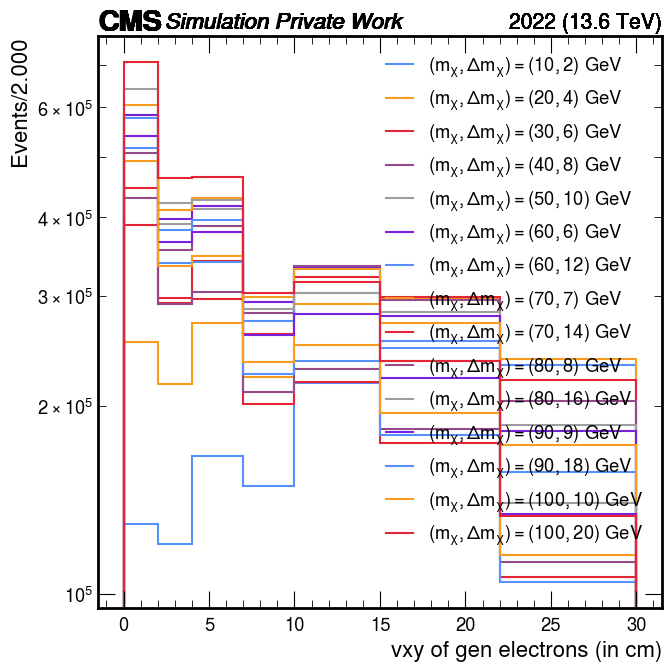

In [28]:
fig, ax = plt.subplots(figsize=(7,7))



# Plot settings
plot_dict = {
    'variable':'gen_ele_vxy',
    'cut': 'cut1',
    'year': 2022
}

style_dict = {
    'fig': fig,
    'ax': ax,
    'rebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': True, 
    'doLogx': False,
    'doDensity': False,
    'doYerr': False, 
    'xlabel': "vxy of gen electrons (in cm)",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
    'ylabel': None,   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'label': None,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
    'flow': None,     # overflow
    'doSave': True,
    'outDir': './plots/signal_2018',
    'outName': f'gen_ele_vxy10_m110.png'
}

samples = {
    10: 
    {
        
        0.2: [100],
        
    },
    
    20: 
    {
        
        0.2: [100],
        
    },
    30: 
    {
       
        0.2: [100]
    },
    40: 
    {
        0.2: [100],
    },
    50:
    {
        
        0.2: [100],
    },
    60:
    {
        
         0.1: [100],
         0.2: [100]
    
    },
    70:
    {    0.1: [100],
         0.2: [100],
    },
    80:
    {    0.1: [100],
         0.2: [100],
    },
    90:
    {    0.1: [100],
         0.2: [100],
    },
    100:
    {    0.1: [100],
         0.2: [100]
    }
 
}

h_list_lpt=[]
h_sum_lpt = None

for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            counts,edges = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
            




print (counts)    
 

                                       mchi  dmchi   ctau    m1    m2  delta  \
sig_2022_Mchi-11p0_dMchi-2p0_ctau-100  11.0    2.0  100.0  10.0  12.0    0.2   

                                                                        name  
sig_2022_Mchi-11p0_dMchi-2p0_ctau-100  sig_2022_Mchi-11p0_dMchi-2p0_ctau-100  
Saved: ./plots/signal_2018/match_ele_gen_vxy10_m110.png
                                       mchi  dmchi   ctau    m1    m2  delta  \
sig_2022_Mchi-22p0_dMchi-4p0_ctau-100  22.0    4.0  100.0  20.0  24.0    0.2   

                                                                        name  
sig_2022_Mchi-22p0_dMchi-4p0_ctau-100  sig_2022_Mchi-22p0_dMchi-4p0_ctau-100  
Saved: ./plots/signal_2018/match_ele_gen_vxy10_m110.png
                                       mchi  dmchi   ctau    m1    m2  delta  \
sig_2022_Mchi-33p0_dMchi-6p0_ctau-100  33.0    6.0  100.0  30.0  36.0    0.2   

                                                                        name  
sig_2022_M

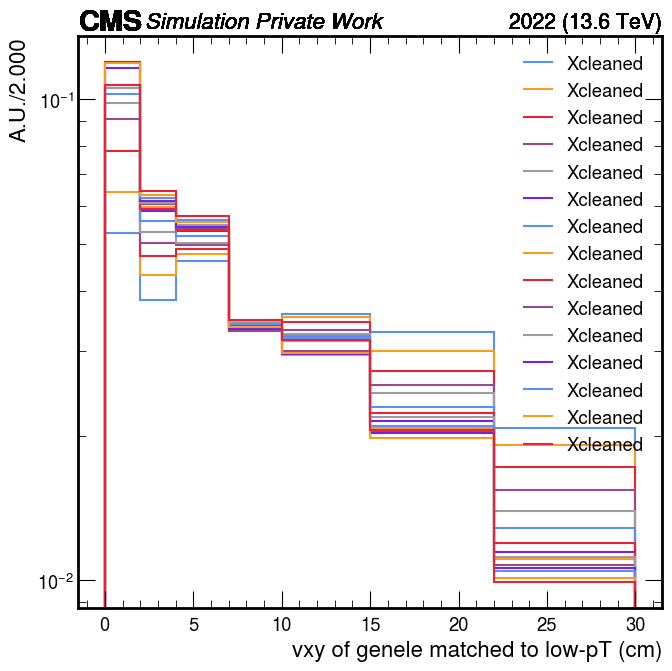

In [29]:
fig, ax = plt.subplots(figsize=(7,7))

plot_dict = {'variable': 'vxy_genElePos_Lpt', 'cut': 'cut1', 'year': 2022}

style_dict = {
    'fig': fig,
    'ax': ax,
    'rebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': True, 
    'doLogx': False,
    'doDensity': True,
    'doYerr': False, 
    #'xlabel': "pT of gen electrons(matched to 'R')",  
    'xlabel': "vxy of genele matched to low-pT (cm)",              # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
    'ylabel': None,   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'label': 'Xcleaned'  ,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
    'flow': None,     # overflow
    'doSave': True,
    'outDir': './plots/signal_2018',
    'outName': f'match_ele_gen_vxy10_m110.png'
}

samples = {
    10: 
    {
        
        0.2: [100],
        
    },
    
    20: 
    {
        
        0.2: [100],
        
    },
    30: 
    {
       
        0.2: [100]
    },
    40: 
    {
        0.2: [100],
    },
    50:
    {
        
        0.2: [100],
    },
    60:
    {
        
         0.1: [100],
         0.2: [100]
    
    },
    70:
    {    0.1: [100],
         0.2: [100],
    },
    80:
    {    0.1: [100],
         0.2: [100],
    },
    90:
    {    0.1: [100],
         0.2: [100],
    },
    100:
    {    0.1: [100],
         0.2: [100]
    }
 
}
h_list_lpt=[]
h_sum_lpt = None

for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            counts_lpt,edges_lpt = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
            bins_lpt = (edges_lpt[:-1] + edges_lpt[1:])*(0.5)

print (counts_lpt)    
 

                                       mchi  dmchi   ctau    m1    m2  delta  \
sig_2022_Mchi-11p0_dMchi-2p0_ctau-100  11.0    2.0  100.0  10.0  12.0    0.2   

                                                                        name  
sig_2022_Mchi-11p0_dMchi-2p0_ctau-100  sig_2022_Mchi-11p0_dMchi-2p0_ctau-100  
Saved: ./plots/signal_2018/match_ele_gen_vxy10_m110.png
                                       mchi  dmchi   ctau    m1    m2  delta  \
sig_2022_Mchi-22p0_dMchi-4p0_ctau-100  22.0    4.0  100.0  20.0  24.0    0.2   

                                                                        name  
sig_2022_Mchi-22p0_dMchi-4p0_ctau-100  sig_2022_Mchi-22p0_dMchi-4p0_ctau-100  
Saved: ./plots/signal_2018/match_ele_gen_vxy10_m110.png
                                       mchi  dmchi   ctau    m1    m2  delta  \
sig_2022_Mchi-33p0_dMchi-6p0_ctau-100  33.0    6.0  100.0  30.0  36.0    0.2   

                                                                        name  
sig_2022_M

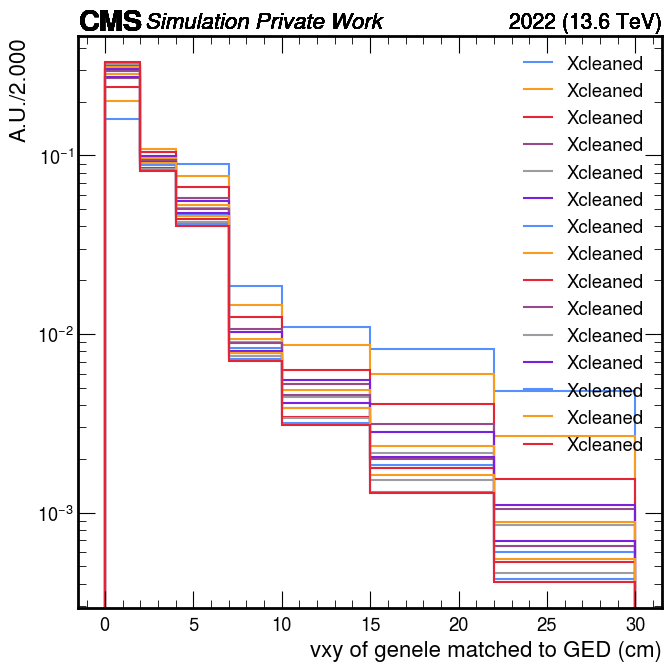

In [30]:
fig, ax = plt.subplots(figsize=(7,7))

plot_dict = {'variable': 'vxy_genElePos_GED', 'cut': 'cut1', 'year': 2022}

style_dict = {
    'fig': fig,
    'ax': ax,
    'rebin': None,
    'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
    'doLogy': True, 
    'doLogx': False,
    'doDensity': True,
    'doYerr': False, 
    #'xlabel': "pT of gen electrons(matched to 'R')",  
    'xlabel': "vxy of genele matched to GED (cm)",              # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
    'ylabel': None,   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
    'label': 'Xcleaned'  ,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
    'flow': None,     # overflow
    'doSave': True,
    'outDir': './plots/signal_2018',
    'outName': f'match_ele_gen_vxy10_m110.png'
}

samples = {
    10: 
    {
        
        0.2: [100],
        
    },
    
    20: 
    {
        
        0.2: [100],
        
    },
    30: 
    {
       
        0.2: [100]
    },
    40: 
    {
        0.2: [100],
    },
    50:
    {
        
        0.2: [100],
    },
    60:
    {
        
         0.1: [100],
         0.2: [100]
    
    },
    70:
    {    0.1: [100],
         0.2: [100],
    },
    80:
    {    0.1: [100],
         0.2: [100],
    },
    90:
    {    0.1: [100],
         0.2: [100],
    },
    100:
    {    0.1: [100],
         0.2: [100]
    }
 
}
h_list_lpt=[]
h_sum_lpt = None
for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            counts_ged,edges_ged = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
            bins_ged = (edges_ged[:-1] + edges_ged[1:])*(0.5)

            

print (counts_ged)
print (bins_ged)


 

In [31]:
total = counts_lpt + counts_ged

In [32]:
def eff_determine_unc(n, d):
    eff = np.divide(n, d)
    unc = hist.intervals.ratio_uncertainty(n, d, 'efficiency')
    return eff, unc


efficiency_lpt, unc_lpt = eff_determine_unc(counts_lpt, counts)
efficiency_ged, unc_ged = eff_determine_unc(counts_ged, counts)

efficiency_total, unc_total = eff_determine_unc(total, counts)


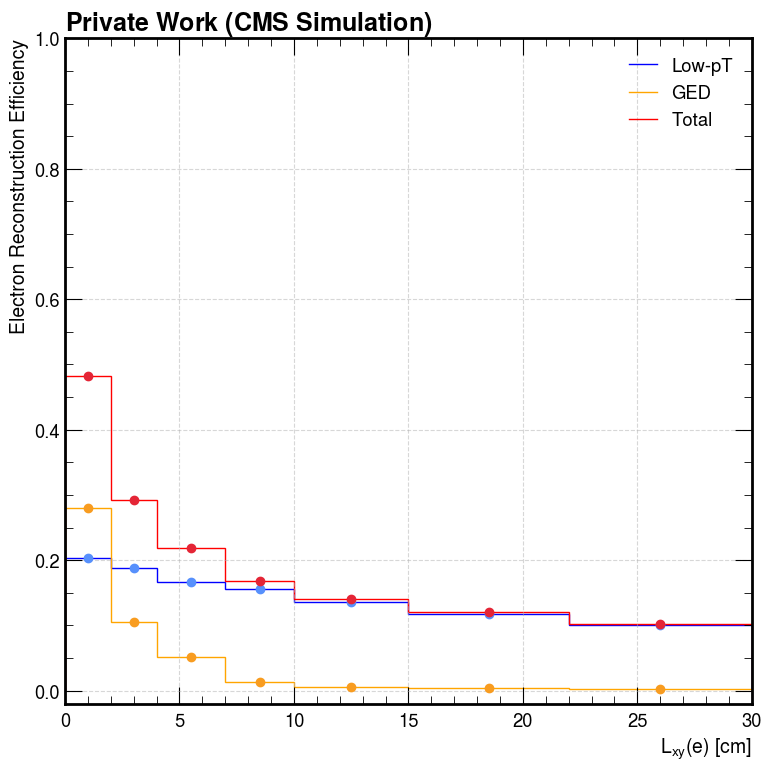

In [34]:
plt.figure(figsize=(8,8))

# Low-pT (No x-cleaning)
plt.stairs(
    efficiency_lpt,
    edges,       
    color='blue',
    linewidth=1,
    label='Low-pT'
)
plt.errorbar(
    bins_lpt,
    efficiency_lpt,
    yerr=unc_lpt,
    fmt='o',
    ecolor='blue',
    linestyle='None',
    elinewidth=1,
    capsize=3
)

plt.stairs(
    efficiency_ged,
    edges,       
    color='orange',
    linewidth=1,
    label='GED'
)
plt.errorbar(
    bins_ged,
    efficiency_ged,
    yerr=unc_ged,
    fmt='o',
    ecolor='orange',
    linestyle='None',
    elinewidth=1,
    capsize=3
)

plt.stairs(
    efficiency_total,
    edges,       
    color='red',
    linewidth=1,
    label='Total'
)
plt.errorbar(
    bins_ged,
    efficiency_total,
    yerr=unc_total,
    fmt='o',
    ecolor='red',
    linestyle='None',
    elinewidth=1,
    capsize=3
)


# Axis styling
plt.ylim(-0.02, 1.00)
plt.xlabel(r"$L_{xy}(e)$ [cm]", fontsize=14)
plt.ylabel("Electron Reconstruction Efficiency", fontsize=14)

plt.grid(True, which='major', linestyle='--', alpha=0.5)

# Title (only)
plt.title(
    r"$\bf{Private\ Work\ (CMS\ Simulation)}$",
    fontsize=18,
    loc='left'
)

plt.xlim(0,30)
plt.legend()
plt.tight_layout()
plt.show()